<a href="https://colab.research.google.com/github/KostantinDubnitskyi/Methodd/blob/main/%D0%9B%D0%A04_(%D0%94%D1%83%D0%B1%D0%BD%D0%B8%D1%86%D1%8C%D0%BA%D0%B8%D0%B9_4_8).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [ ]:
from google.colab import files

uploaded = files.upload()

import pandas as pd
df = pd.read_csv('CarPrice_Assignment.csv')

Saving CarPrice_Assignment.csv to CarPrice_Assignment.csv


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew

df = pd.read_csv('CarPrice_Assignment.csv')

print("Кількість об'єктів:", df.shape[0])
print("Кількість ознак:", df.shape[1])
print("\nНазви стовпців:")
print(df.columns.tolist())
print("\nТипи даних:")
print(df.dtypes)
print("\nЦільова змінна: price")

df.describe()

Кількість об'єктів: 205
Кількість ознак: 26

Назви стовпців:
['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']

Типи даних:
car_ID                int64
symboling             int64
CarName              object
fueltype             object
aspiration           object
doornumber           object
carbody              object
drivewheel           object
enginelocation       object
wheelbase           float64
carlength           float64
carwidth            float64
carheight           float64
curbweight            int64
enginetype           object
cylindernumber       object
enginesize            int64
fuelsystem           object
boreratio           float64
stroke              float64
compressionratio    f

,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


Перевірив розмір датасету, назви стовпців і типи даних. З'ясував, що датасет містить 205 об'єктів і 26 ознак, цільова змінна price - неперервна числова, тому задача регресійна.

## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [ ]:
missing = pd.DataFrame({
    "count": df.isna().sum(),
    "share": df.isna().mean(),
}).sort_values("share", ascending=False)

missing

print("Повних дублікатів (без car_ID):", df.drop(columns="car_ID").duplicated().sum())
print(df.nunique())

Повних дублікатів (без car_ID): 0
car_ID              205
symboling             6
CarName             147
fueltype              2
aspiration            2
doornumber            2
carbody               5
drivewheel            3
enginelocation        2
wheelbase            53
carlength            75
carwidth             44
carheight            49
curbweight          171
enginetype            7
cylindernumber        7
enginesize           44
fuelsystem            8
boreratio            38
stroke               37
compressionratio     32
horsepower           59
peakrpm              23
citympg              29
highwaympg           30
price               189
dtype: int64


Перевірив дані на пропуски та дублікати за змістовими ознаками (без car_ID) і з'ясував, що ні того, ні іншого немає.

## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [ ]:
car_ids = df["car_ID"]
df = df.drop(columns="car_ID")

df.head()

,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,168.8,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,168.8,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,171.2,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,176.6,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,176.6,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


Проаналізував призначення car_ID і з'ясував він не пов'язаний із ціною авто. Зберіг його окремо, щоб не використовувати як ознаку під час навчання.

## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


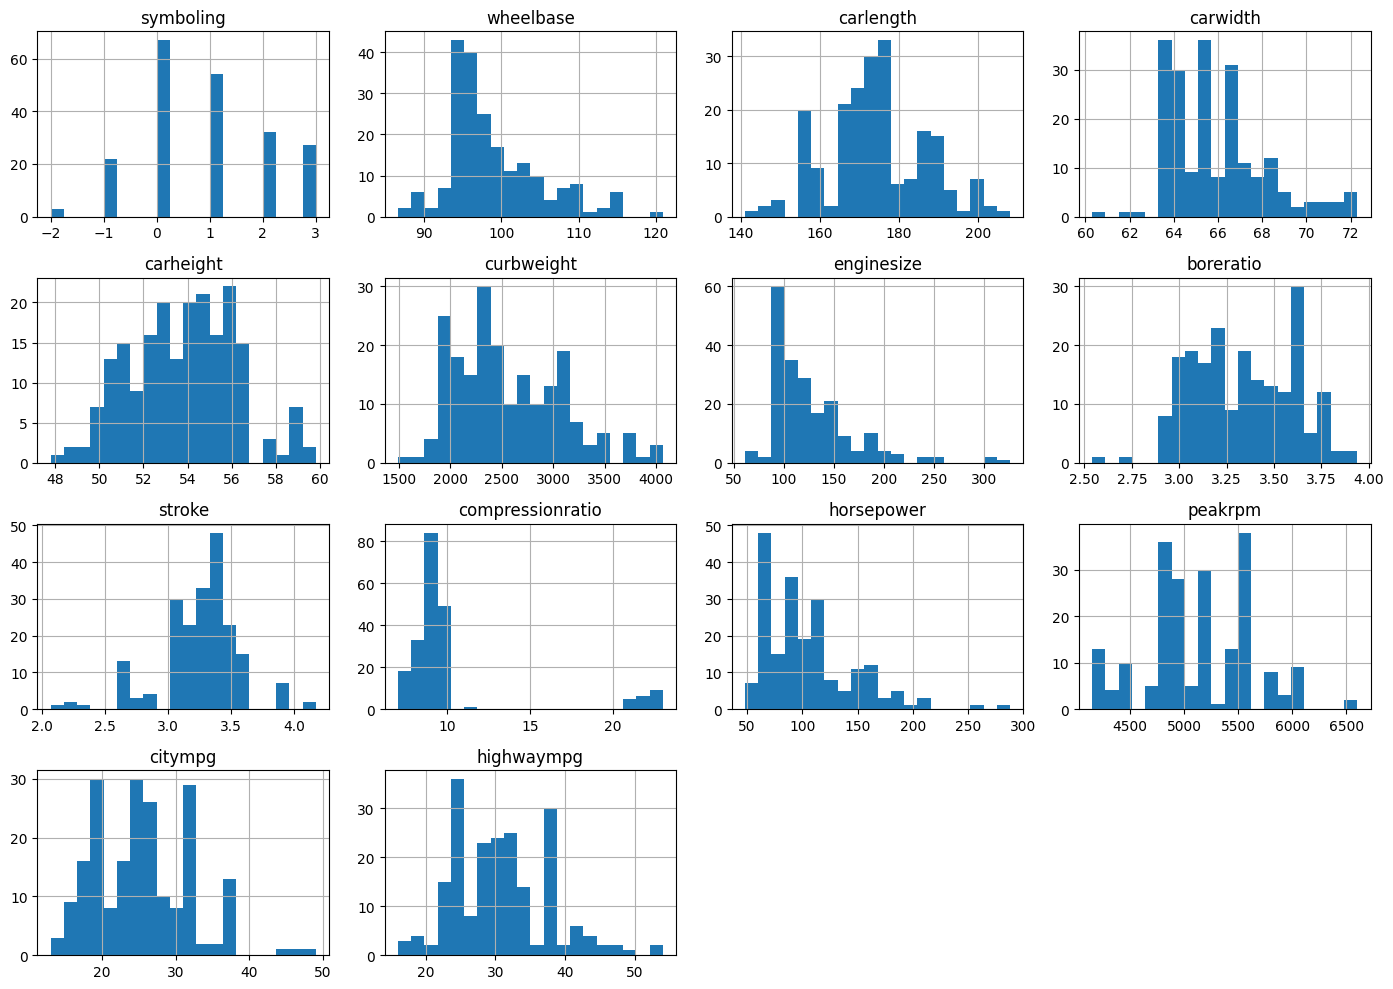

Асиметрія ознак:
compressionratio    2.591720
enginesize          1.933375
horsepower          1.395006
wheelbase           1.042514
carwidth            0.897375
stroke             -0.684648
curbweight          0.676402
citympg             0.658838
highwaympg          0.536038
symboling           0.209525
carlength           0.154810
peakrpm             0.074608
carheight           0.062660
boreratio           0.020009
dtype: float64


In [ ]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
numeric_cols.remove("price")

df[numeric_cols].hist(figsize=(14, 10), bins=20)
plt.tight_layout()
plt.show()

skew_values = df[numeric_cols].apply(skew).sort_values(key=np.abs, ascending=False)
print("Асиметрія ознак:")
print(skew_values)

Побудував гістограми й порахував асиметрію числових ознак. З'ясував, що найбільшу асиметрію мають compressionratio (2.59), enginesize (1.93) та horsepower (1.40).

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [ ]:
from sklearn.model_selection import train_test_split

x = df.drop(columns="price")
y = df["price"]

x_train, x_test, y_train, y_test, id_train, id_test = train_test_split(
    x, y, car_ids, test_size=0.2, random_state=42
)

print(x_train.shape, x_test.shape)

(164, 24) (41, 24)


Поділив дані на train (164 рядки) і test (41 рядок) у співвідношенні 80/20 з фіксованим random_state.
Перевірив розміри вибірок і з'ясував, що поділ відтворюваний.

## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [ ]:
continuous_cols = [c for c in numeric_cols if x_train[c].nunique() > 10]

for col in continuous_cols:
    q1 = x_train[col].quantile(0.25)
    q3 = x_train[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    n_outliers = ((x_train[col] < lower) | (x_train[col] > upper)).sum()
    print(f"{col}: межі [{lower:.2f}, {upper:.2f}], викидів: {n_outliers}")

    x_train[col] = x_train[col].clip(lower, upper)
    x_test[col] = x_test[col].clip(lower, upper)

wheelbase: межі [83.10, 113.50], викидів: 6
carlength: межі [141.89, 207.99], викидів: 0
carwidth: межі [60.42, 70.42], викидів: 10
carheight: межі [46.46, 60.96], викидів: 0
curbweight: межі [998.62, 4103.62], викидів: 0
enginesize: межі [33.50, 205.50], викидів: 7
boreratio: межі [2.56, 4.12], викидів: 1
stroke: межі [2.66, 3.86], викидів: 16
compressionratio: межі [7.40, 10.60], викидів: 20
horsepower: межі [4.75, 182.75], викидів: 7
peakrpm: межі [3750.00, 6550.00], викидів: 2
citympg: межі [2.50, 46.50], викидів: 0
highwaympg: межі [11.50, 47.50], викидів: 1


Порахував межі IQR для кожної неперервної ознаки та з'ясував, що найбільше потенційних викидів у compressionratio і stroke. Через невеликий розмір датасету обмежив значення межами IQR, визначеними лише на train.

## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


In [ ]:
correlation = x_train[numeric_cols].corr()
correlation.round(2)

target_corr = x_train[numeric_cols].join(y_train).corr()["price"].drop("price")
print("Кореляція з price:")
print(target_corr.sort_values(key=np.abs, ascending=False))

strong_pairs = []
for i in range(len(numeric_cols)):
    for j in range(i + 1, len(numeric_cols)):
        r = correlation.iloc[i, j]
        if abs(r) > 0.85:
            strong_pairs.append((numeric_cols[i], numeric_cols[j], round(r, 3)))

print("\nСильно корельовані пари:", strong_pairs)

features_to_drop = set()
for f1, f2, r in strong_pairs:
    if abs(target_corr[f1]) >= abs(target_corr[f2]):
        features_to_drop.add(f2)
    else:
        features_to_drop.add(f1)

print("Видаляємо:", features_to_drop)

x_train = x_train.drop(columns=list(features_to_drop))
x_test = x_test.drop(columns=list(features_to_drop))

Кореляція з price:
enginesize          0.845969
curbweight          0.824212
horsepower          0.807101
carwidth            0.731623
highwaympg         -0.716460
citympg            -0.711245
carlength           0.652071
boreratio           0.547119
wheelbase           0.504036
peakrpm            -0.069658
compressionratio   -0.060275
carheight           0.044458
stroke             -0.006416
symboling          -0.005183
Name: price, dtype: float64

Сильно корельовані пари: [('wheelbase', 'carlength', np.float64(0.867)), ('carlength', 'curbweight', np.float64(0.866)), ('carwidth', 'curbweight', np.float64(0.858)), ('citympg', 'highwaympg', np.float64(0.964))]
Видаляємо: {'wheelbase', 'carwidth', 'citympg', 'carlength'}


Побудував кореляційну матрицю і знайшов чотири пари сильно корельованих ознак. Порівняв силу зв'язку кожної ознаки з price і з'ясував, яку з пари залишити. Видалив wheelbase, carlength, carwidth, citympg.

## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [ ]:
from sklearn.preprocessing import PowerTransformer, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

numeric_cols = [c for c in numeric_cols if c not in features_to_drop]
continuous_features = [c for c in continuous_cols if c not in features_to_drop]
symboling_feature = ["symboling"]
categorical_features = x_train.select_dtypes(exclude=[np.number]).columns.tolist()

print("Категоріальні ознаки:", categorical_features)

numeric_pipe = Pipeline([
    ("yeo_johnson", PowerTransformer(method="yeo-johnson")),
    ("scale", StandardScaler()),
])

symboling_pipe = Pipeline([
    ("scale", StandardScaler()),
])

categorical_pipe = Pipeline([
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, continuous_features),
    ("symboling", symboling_pipe, symboling_feature),
    ("cat", categorical_pipe, categorical_features),
])

Категоріальні ознаки: ['CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem']


Об'єднав усі перетворення в один ColumnTransformer, який навчається лише на x_train. Перевірив список категоріальних ознак і з'ясував, що CarName теж потрапляє туди як категоріальна, через що після One-Hot Encoding кількість стовпців зросла до 171.

## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [ ]:
yj = PowerTransformer(method="yeo-johnson")
transformed = yj.fit_transform(x_train[continuous_features])
transformed_df = pd.DataFrame(transformed, columns=continuous_features)

skew_before = x_train[continuous_features].apply(skew)
skew_after = transformed_df.apply(skew)

skew_compare = pd.DataFrame({"before": skew_before, "after": skew_after})
skew_compare

,before,after
carheight,0.027896,-0.005123
curbweight,0.705900,0.049436
enginesize,0.953569,0.044423
boreratio,0.062385,-0.005887
stroke,-0.393954,0.015701
compressionratio,0.055199,0.004828
horsepower,0.842934,0.065672
peakrpm,0.039408,-0.003556
highwaympg,0.241526,-0.012076


Застосував Yeo-Johnson до train і порівняв асиметрію до і після трансформації. З'ясував, що значення асиметрії стали набагато ближчими до нуля, що означанє що трансформація виявилась ефективною

## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [ ]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

models = {
    "Linear Regression": Pipeline([
        ("prep", preprocessor),
        ("reg", LinearRegression()),
    ]),
    "Ridge": Pipeline([
        ("prep", preprocessor),
        ("reg", Ridge(alpha=1.0)),
    ]),
    "Lasso": Pipeline([
        ("prep", preprocessor),
        ("reg", Lasso(alpha=1.0, max_iter=20000)),
    ]),
    "Random Forest": Pipeline([
        ("prep", preprocessor),
        ("reg", RandomForestRegressor(random_state=42)),
    ]),
    "Gradient Boosting": Pipeline([
        ("prep", preprocessor),
        ("reg", GradientBoostingRegressor(random_state=42)),
    ]),
    "SVR": Pipeline([
        ("prep", preprocessor),
        ("reg", SVR(kernel="rbf", C=10000, epsilon=200)),
    ]),
}

for name, model in models.items():
    model.fit(x_train, y_train)

print("Усі шість моделей навчено.")

Усі шість моделей навчено.


Навчив усі шість моделей в єдиному Pipeline з однаковою попередньою обробкою даних. Це дозволило порівняти моделі правильно.

## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    root_mean_squared_error,
    r2_score,
)

def regression_metrics(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'MSE': mean_squared_error(y_true, y_pred),
        'RMSE': root_mean_squared_error(y_true, y_pred),
        'R2': r2_score(y_true, y_pred),
        'MAPE': (np.abs(y_true - y_pred) / y_true).mean() * 100
    }

results = []
predictions = {}

for name, model in models.items():
    pred = model.predict(x_test)
    predictions[name] = pred

    metrics = regression_metrics(y_test, pred)
    metrics["model"] = name
    results.append(metrics)

results_table = pd.DataFrame(results).set_index("model")[["R2", "MAE", "MSE", "MAPE"]]
results_table.sort_values("R2", ascending=False)

,R2,MAE,MSE,MAPE
model,,,,
Random Forest,0.949372,1447.341293,3.996761e+06,10.363347
Gradient Boosting,0.929565,1684.462050,5.560430e+06,12.590929
SVR,0.866072,2147.754473,1.057284e+07,17.057894
Ridge,0.795688,2712.715517,1.612918e+07,23.064380
Lasso,0.706085,3088.990470,2.320280e+07,22.608482
Linear Regression,0.548047,4078.301976,3.567898e+07,29.972750


Порахував R2, MAE, MSE та MAPE для кожної моделі та відсортував результати. З'ясував, що найкращий результат показав Random Forest (R2 = 0.9494), а найгірший - Linear Regression (R2 = 0.5480).

## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


Price - це неперервна величина, тому це задача регресії, а не класифікації. Logistic Regression натомість прогнозує ймовірність належності до класу, а не конкретну ціну, тому для цієї задачі вона не підходить. Усі моделі в роботі - регресійні, тому підходять для задачі.

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


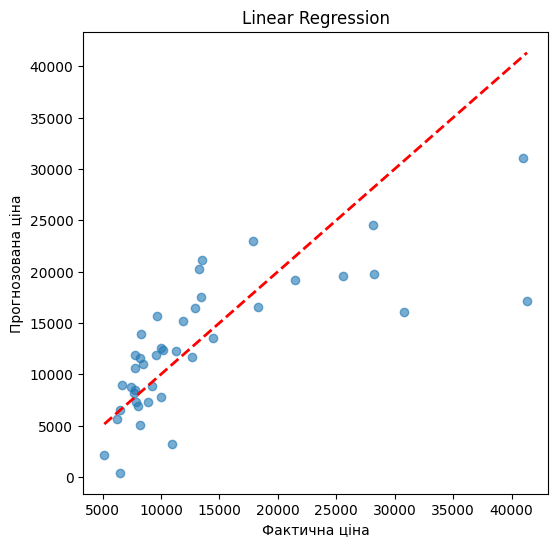

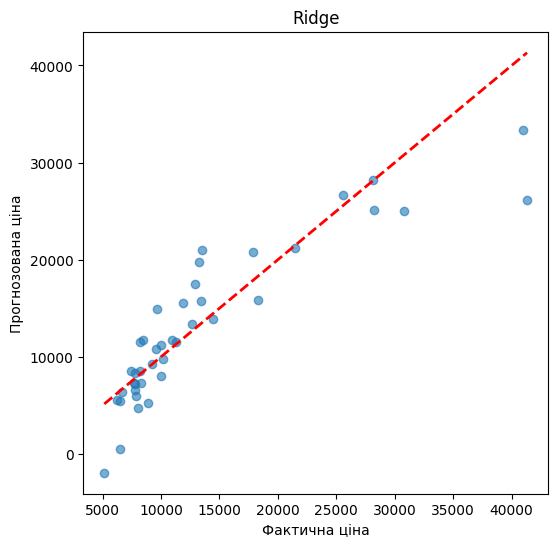

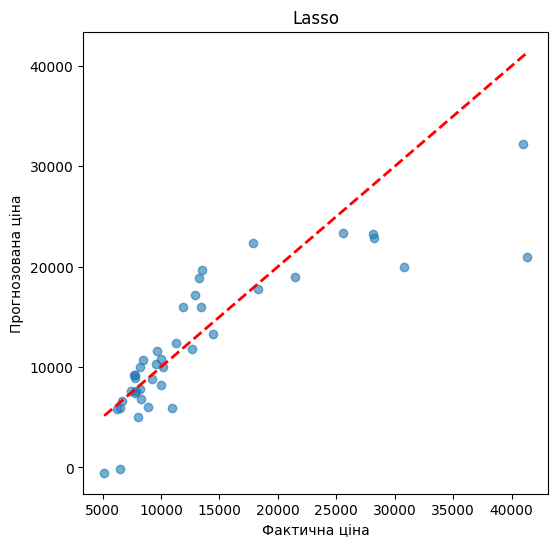

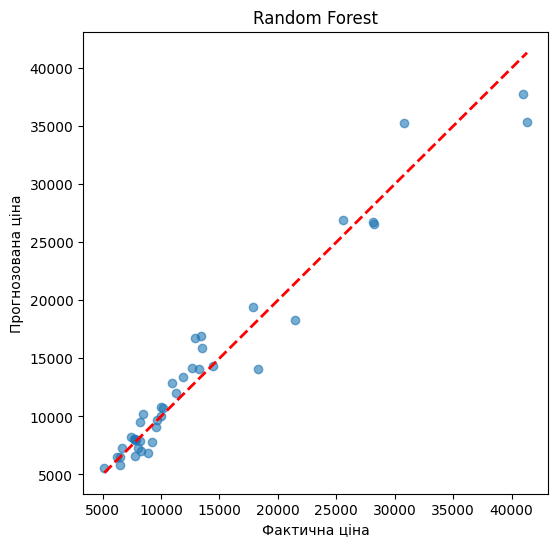

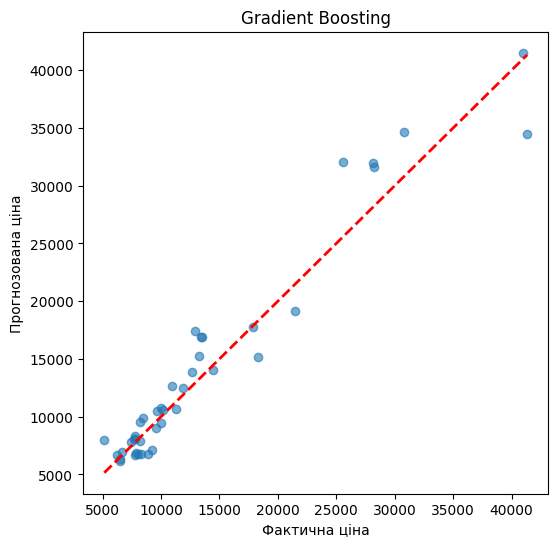

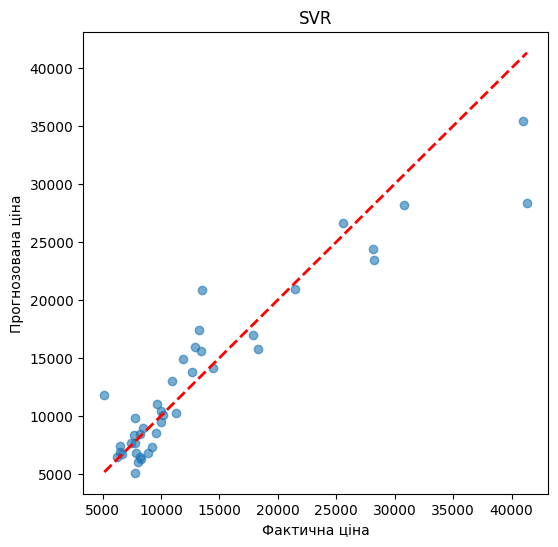

In [ ]:
for name, pred in predictions.items():
    plt.figure(figsize=(6, 6))
    plt.scatter(y_test, pred, alpha=0.6)
    plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2)
    plt.xlabel("Фактична ціна")
    plt.ylabel("Прогнозована ціна")
    plt.title(name)
    plt.show()

Побудував графіки фактичних і прогнозованих значень для кожної моделі. З'ясував, що точки Random Forest і Gradient Boosting лежать найближче до лінії ідеального прогнозу, тоді як у Linear Regression і Lasso розкид дуже великий.

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [ ]:
rf_pred = predictions["Random Forest"]

sample_idx = x_test.sample(10, random_state=42).index

sample_table = pd.DataFrame({
    "car_ID": id_test.loc[sample_idx].values,
    "actual_price": y_test.loc[sample_idx].values,
    "predicted_price": pd.Series(rf_pred, index=x_test.index).loc[sample_idx].values,
})

sample_table["abs_error"] = np.abs(sample_table["actual_price"] - sample_table["predicted_price"])
sample_table["abs_error_%"] = sample_table["abs_error"] / sample_table["actual_price"] * 100

sample_table

,car_ID,actual_price,predicted_price,abs_error,abs_error_%
0,26,6692.0,7298.805,606.805,9.067618
1,176,9988.0,10798.650,810.650,8.116239
2,148,10198.0,10714.570,516.570,5.065405
3,17,41315.0,35310.690,6004.310,14.533003
4,69,28248.0,26595.285,1652.715,5.850733
5,147,7463.0,8230.000,767.000,10.277368
6,144,9960.0,10065.200,105.200,1.056225
7,85,14489.0,14346.480,142.520,0.983643
8,195,12940.0,16765.650,3825.650,29.564529
9,160,7788.0,7995.560,207.560,2.665126


Сформував таблицю прогнозів Random Forest для 10 випадкових автомобілів і порахував похибку у відсотках. З'ясував, що для більшості авто похибка відносно невелика, але для окремих об'єктів вона значно більша - ймовірно, через нетипову комбінацію характеристик.

## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


У роботі побудовано й порівняно шість регресійних моделей для прогнозування ціни автомобіля: Linear Regression, Ridge, Lasso, Random Forest, Gradient Boosting та SVR. Усі моделі навчались в єдиній схемі Pipeline з однаковою попередньою обробкою даних.

Найкращий результат за всіма метриками показав Random Forest (R2 = 0.9494, MAE = 1447.34, MAPE = 10.36%), а найгірший - Linear Regression (R2 = 0.5480, MAE = 4078.29, MAPE = 29.97%). Ансамблеві методи (Random Forest, Gradient Boosting) випередили лінійні моделі з великим відривом.

Велика різниця в якості пояснюється кількістю ознак після кодування: категоріальна ознака CarName містить 124 унікальних значення в train, тому після One-Hot Encoding датасет розширився до 171 стовпця. Для лінійних моделей це означає майже стільки ж ознак, скільки й спостережень, що робить оцінку коефіцієнтів нестабільною і знижує якість прогнозу на test.

Ансамблеві моделі (Random Forest, Gradient Boosting) виявились стійкішими до такої кількості розріджених ознак. Явних ознак перенавчання на цьому єдиному train/test розбитті не виявлено.

Попередня обробка даних (усунення мультиколінеарності, обробка викидів через IQR, трансформація Yeo-Johnson) позитивно вплинула на якість усіх моделей, однак величезна кардинальність ознаки CarName залишилась неусуненою проблемою, яка найбільше вдарила по лінійних моделях.

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
